In [13]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier, XGBRegressor
import matplotlib.pyplot as plt

In [14]:
import pandas as pd

# # Load the datasets
# vei_df = pd.read_csv('/content/mumbai_VEI_2015_2025.csv')
# indices_df = pd.read_csv('/content/mumbai_remote_sensing_indices_2023 - mumbai_remote_sensing_indices_2023.csv')
# flood_features_df = pd.read_csv('/content/mumbai_daily_flood_features_2004_2023.csv')
path1 = r'C:\Users\Srikar\Downloads\Mumbai_Flood_Predcition__Model_Approach\mumbai_VEI_2015_2025.csv'
path2 = r'C:\Users\Srikar\Downloads\Mumbai_Flood_Predcition__Model_Approach\mumbai_remote_sensing_indices_2023 - mumbai_remote_sensing_indices_2023.csv'
path3 = r'C:\Users\Srikar\Downloads\Mumbai_Flood_Predcition__Model_Approach\mumbai_daily_flood_features_2004_2023.csv'
vei_df = pd.read_csv(path1)
indices_df = pd.read_csv(path2)
flood_features_df = pd.read_csv(path3)

# Display basic info and shapes
print(f"VEI Dataset shape: {vei_df.shape}")
print(f"Remote Sensing Indices Dataset shape: {indices_df.shape}")
print(f"Daily Flood Features Dataset shape: {flood_features_df.shape}")

VEI Dataset shape: (672, 3)
Remote Sensing Indices Dataset shape: (849, 3)
Daily Flood Features Dataset shape: (7304, 18)


In [15]:
# Convert Date column to datetime to make sure date handling is clean
vei_df['Date'] = pd.to_datetime(vei_df['Date'])

# Group by Date and aggregate by taking the mean of Mean_VEI and max of Max_VEI
vei_df_unique = vei_df.groupby('Date').agg({
    'Mean_VEI': 'mean',
    'Max_VEI': 'max'
}).reset_index()

# Display new shape and preview
print(f"Original shape: {vei_df.shape}")
print(f"New shape with unique dates: {vei_df_unique.shape}")

Original shape: (672, 3)
New shape with unique dates: (343, 3)


In [16]:
# Convert date column to datetime
indices_df['date'] = pd.to_datetime(indices_df['date'], format='%d-%m-%Y')

# Group by date and aggregate using mean for the indices
indices_df_unique = indices_df.groupby('date').agg({
    'siltation_index': 'mean',
    'clogging_fdi': 'mean'
}).reset_index()

# Display shape changes and a preview
print(f"Original indices_df shape: {indices_df.shape}")
print(f"New indices_df_unique shape: {indices_df_unique.shape}")

Original indices_df shape: (849, 3)
New indices_df_unique shape: (246, 3)


In [17]:
# Convert date column to datetime
flood_features_df['date'] = pd.to_datetime(flood_features_df['date'], format='%d-%m-%Y')

# Filter from Jan 1, 2015 to Dec 31, 2023
start_date = '2015-01-01'
end_date = '2023-12-31'
flood_features_filtered = flood_features_df[
    (flood_features_df['date'] >= start_date) & (flood_features_df['date'] <= end_date)
].reset_index(drop=True)

# Display new shape and a preview
print(f"Original flood features shape: {flood_features_df.shape}")
print(f"Filtered flood features shape: {flood_features_filtered.shape}")

Original flood features shape: (7304, 18)
Filtered flood features shape: (3286, 18)


In [18]:
# Rename 'Date' in vei_df_unique to lowercase 'date' for consistent merging
vei_df_clean = vei_df_unique.rename(columns={'Date': 'date'})

# Merge flood_features_filtered with vei_df_clean
mumbai_merged = pd.merge(flood_features_filtered, vei_df_clean, on='date', how='left')

# Merge the result with indices_df_unique
mumbai_merged = pd.merge(mumbai_merged, indices_df_unique, on='date', how='left')

# Print information and display the merged data
print(f"Merged Dataset shape: {mumbai_merged.shape}")
print(f"Date Range: {mumbai_merged['date'].min().date()} to {mumbai_merged['date'].max().date()}")

Merged Dataset shape: (3286, 22)
Date Range: 2015-01-01 to 2023-12-30


In [19]:
# Check missing values before spline interpolation
print("Missing values before interpolation:")
print(mumbai_merged[['Mean_VEI', 'Max_VEI', 'siltation_index', 'clogging_fdi']].isnull().sum())

# Ensure 'date' is set as index to allow time-based or index-based interpolation
mumbai_merged.set_index('date', inplace=True)

# Interpolate the indices and VEI columns using cubic spline interpolation
columns_to_fill = ['Mean_VEI', 'Max_VEI', 'siltation_index', 'clogging_fdi']
mumbai_merged[columns_to_fill] = mumbai_merged[columns_to_fill].interpolate(method='cubicspline')

# Handle any boundary missing values at the absolute beginning or end of the series using bfill/ffill
mumbai_merged[columns_to_fill] = mumbai_merged[columns_to_fill].bfill().ffill()

# Reset index back
mumbai_merged.reset_index(inplace=True)

# Check missing values after interpolation
print("\nMissing values after spline interpolation:")
print(mumbai_merged[['Mean_VEI', 'Max_VEI', 'siltation_index', 'clogging_fdi']].isnull().sum())

Missing values before interpolation:
Mean_VEI           3031
Max_VEI            3031
siltation_index    3040
clogging_fdi       3040
dtype: int64

Missing values after spline interpolation:
Mean_VEI           0
Max_VEI            0
siltation_index    0
clogging_fdi       0
dtype: int64


In [20]:
mumbai_flood_dates = [
    "2015-06-19", "2016-06-20", "2016-06-21", "2016-06-22", "2016-08-05",
    "2017-08-29", "2017-08-30", "2018-06-25", "2018-07-09", "2018-07-10",
    "2019-07-01", "2019-07-02", "2019-07-26", "2019-07-27", "2019-09-04",
    "2019-09-05", "2020-08-04", "2020-08-05", "2020-09-22", "2020-09-23",
    "2020-09-24", "2021-06-09", "2021-07-16", "2021-07-17", "2021-07-18",
    "2021-09-23", "2022-07-05", "2022-07-06", "2022-07-07", "2022-07-08",
    "2023-07-26", "2023-07-27"
]


mumbai_merged['flood_label'] = np.where(mumbai_merged['date'].isin(mumbai_flood_dates), 1, 0)

mumbai_merged.to_csv("Mumbai_final_data.csv")

C:\Users\Srikar\AppData\Local\Temp\ipykernel_42984\641413632.py:12: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  mumbai_merged['flood_label'] = np.where(mumbai_merged['date'].isin(mumbai_flood_dates), 1, 0)


In [21]:
# 1. Ensure we are working with our primary dataset copy
mumbai_synthetic = mumbai_merged.copy()

# Convert date column to datetime and extract time indicators for astronomical tide simulation
mumbai_synthetic['date'] = pd.to_datetime(mumbai_synthetic['date'])
t_days = (mumbai_synthetic['date'] - mumbai_synthetic['date'].min()).dt.days

# 2. Simulate Astronomical Tide (semidiurnal/diurnal envelope represented daily)
# We represent the spring-neap tidal cycle (approx 14.77 days lunar cycle variation)
astronomical_envelope = 1.5 + 0.8 * np.sin(2 * np.pi * t_days / 14.77)

# 3. Meteorological Storm Surge / Tidal Influence
# Low surface pressure and high winds/runoff physically increase the local water level (surge)
# Normalize meteorological variables for stable scaling
press_norm = (mumbai_synthetic['surface_pressure_kpa'] - mumbai_synthetic['surface_pressure_kpa'].mean()) / mumbai_synthetic['surface_pressure_kpa'].std()
wind_norm = (mumbai_synthetic['wind_speed_10m_ms'] - mumbai_synthetic['wind_speed_10m_ms'].mean()) / mumbai_synthetic['wind_speed_10m_ms'].std()
runoff_norm = (mumbai_synthetic['surface_runoff_mm'] - mumbai_synthetic['surface_runoff_mm'].mean()) / mumbai_synthetic['surface_runoff_mm'].std()

# Surge is negatively correlated with pressure (inverse barometer effect), and positively with wind and runoff
met_surge = -0.15 * press_norm + 0.1 * wind_norm + 0.2 * runoff_norm

# 4. Combine Astronomical and Meteorological components to create Synthetic Tide (in meters)
np.random.seed(42)
noise = np.random.normal(0, 0.05, len(mumbai_synthetic))
mumbai_synthetic['synthetic_tide_m'] = astronomical_envelope + met_surge + noise

In [22]:
# Define the core columns to calculate rolling statistics for
rolling_cols = [
    'precip_daily_mm',
    'relative_humidity_pct',
    'surface_pressure_kpa',
    'surface_runoff_mm',
    'wind_speed_10m_ms',
    'temp_mean_c'
]

# Sort by date to make sure the rolling windows correspond to consecutive chronological days
mumbai_synthetic = mumbai_synthetic.sort_values('date').reset_index(drop=True)

# Create rolling mean features for 2, 3, 5, and 7 days
windows = [2, 3, 5, 7]
for col in rolling_cols:
    if col in mumbai_synthetic.columns:
        for w in windows:
            col_name = f"{col}_{w}day_mean"
            # Calculate rolling mean, using min_periods=1 so we don't introduce unnecessary NaNs at the start
            mumbai_synthetic[col_name] = mumbai_synthetic[col].rolling(window=w, min_periods=1).mean()

# Verify and display some of the newly created columns
new_cols = [c for c in mumbai_synthetic.columns if any(f"{w}day_mean" in c for w in windows)]
print(f"Generated {len(new_cols)} new rolling window columns.")

Generated 24 new rolling window columns.


In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
import seaborn as sns

all_feat = mumbai_synthetic.columns
# 1. Define features and target
indices_feat = ['Mean_VEI', 'siltation_index', 'clogging_fdi']
target = 'flood_label'

rainfall_feat = [feat for feat in all_feat if feat not in indices_feat and feat != "DCSI"]

# Drop rows where flood_label is NaN (if any)
mumbai_clean = mumbai_synthetic.dropna(subset=[target]).copy()


## Random Forest Classifier

DCSI

In [24]:
X_ind = mumbai_clean[indices_feat]
y = mumbai_clean[target]
ind_scaler = StandardScaler()
X_ind_scaled = ind_scaler.fit_transform(X_ind)

c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(


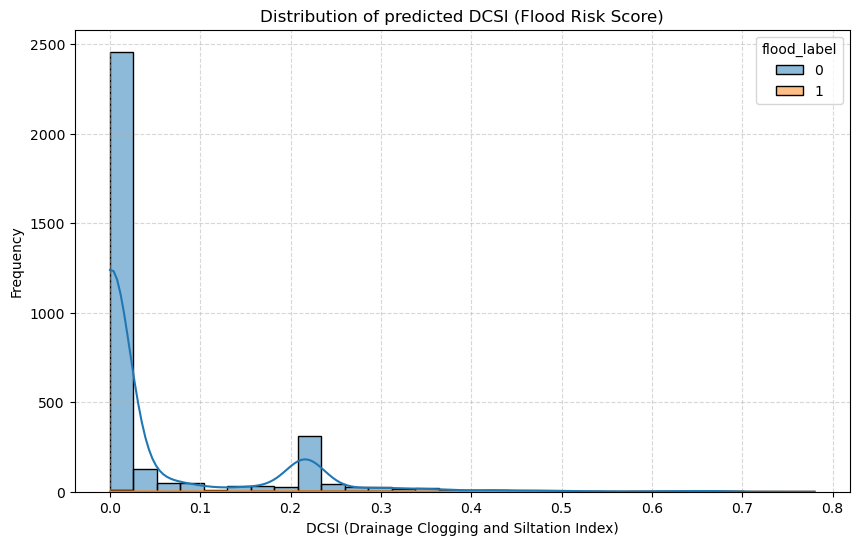

In [25]:
# 2. Train a Random Forest Classifier to output probabilities
# We use cross-validation to get out-of-fold risk scores (DCSI) for each date
rf_dcsi = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Get predicted probabilities for the positive class (flood)
# cross_val_predict gives us unbiased probability estimates across the whole dataset

probabilities = cross_val_predict(rf_dcsi, X_ind_scaled, y, cv=100, method='predict_proba')

# The second column [:, 1] corresponds to the probability of class 1 (flood)
mumbai_clean['DCSI'] = probabilities[:, 1]

# 3. Visualize the distribution of the generated DCSI score
plt.figure(figsize=(10, 6))
sns.histplot(data=mumbai_clean, x='DCSI', hue='flood_label', kde=True, bins=30, multiple='stack')
plt.title('Distribution of predicted DCSI (Flood Risk Score)')
plt.xlabel('DCSI (Drainage Clogging and Siltation Index)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [26]:
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, classification_report, confusion_matrix

# 1. Generate out-of-fold hard class predictions (0 or 1)
predicted_classes = cross_val_predict(rf_dcsi, X_ind_scaled, y, cv=100)

# 2. Extract out-of-fold predicted probabilities for ROC-AUC calculation
predicted_probs = probabilities[:, 1]

# 3. Calculate metrics
accuracy = accuracy_score(y, predicted_classes)
roc_auc = roc_auc_score(y, predicted_probs)
precision = precision_score(y, predicted_classes, zero_division=0)
recall = recall_score(y, predicted_classes, zero_division=0)

# 4. Print metrics
print("=== CLASSIFICATION PERFORMANCE METRICS ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print("\n=== Classification Report ===")
print(classification_report(y, predicted_classes, zero_division=0))

# 5. Confusion Matrix
print("=== Confusion Matrix ===")
print(confusion_matrix(y, predicted_classes))

c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(


=== CLASSIFICATION PERFORMANCE METRICS ===
Accuracy:  0.9860
ROC-AUC:   0.8024
Precision: 0.2083
Recall:    0.1562

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3254
           1       0.21      0.16      0.18        32

    accuracy                           0.99      3286
   macro avg       0.60      0.58      0.59      3286
weighted avg       0.98      0.99      0.99      3286

=== Confusion Matrix ===
[[3235   19]
 [  27    5]]


Rainfall Score

In [27]:
X_rain = mumbai_clean[rainfall_feat]
y = mumbai_clean[target]
rain_scaler = StandardScaler()
X_rain_scaled = rain_scaler.fit_transform(X_ind)

c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(


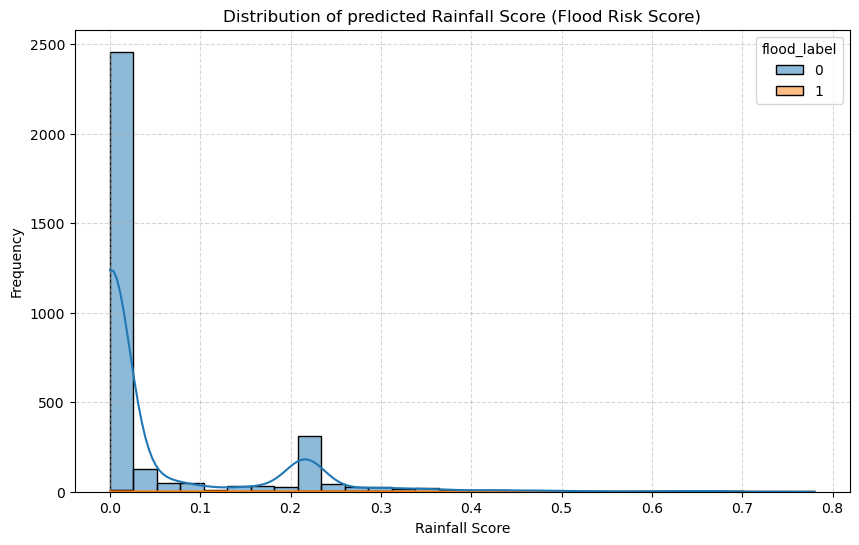

In [28]:
rf_rainfall = RandomForestClassifier(n_estimators = 100, class_weight='balanced', random_state=42)

rain_probs = cross_val_predict(rf_rainfall, X_rain_scaled, y, cv=100, method='predict_proba')

mumbai_clean['Rainfall_score'] = rain_probs[:, 1]

plt.figure(figsize=(10, 6))
sns.histplot(data=mumbai_clean, x='Rainfall_score', hue='flood_label', kde=True, bins=30, multiple='stack')
plt.title('Distribution of predicted Rainfall Score (Flood Risk Score)')
plt.xlabel('Rainfall Score')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [29]:
rain_probabs = cross_val_predict(rf_rainfall, X_rain_scaled, y, cv=100)
rain_pred = rain_probs[:, 1]

accuracy = accuracy_score(y, rain_probabs)
roc_auc = roc_auc_score(y, rain_pred)
precision = precision_score(y, rain_probabs, zero_division=0)
recall = recall_score(y, rain_probabs, zero_division=0)

# 4. Print metrics
print("=== CLASSIFICATION PERFORMANCE METRICS ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print("\n=== Classification Report ===")
print(classification_report(y, rain_probabs, zero_division=0))

# 5. Confusion Matrix
print("=== Confusion Matrix ===")
print(confusion_matrix(y, rain_probabs))

c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(


=== CLASSIFICATION PERFORMANCE METRICS ===
Accuracy:  0.9860
ROC-AUC:   0.8024
Precision: 0.2083
Recall:    0.1562

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3254
           1       0.21      0.16      0.18        32

    accuracy                           0.99      3286
   macro avg       0.60      0.58      0.59      3286
weighted avg       0.98      0.99      0.99      3286

=== Confusion Matrix ===
[[3235   19]
 [  27    5]]


Final Model

In [30]:
from sklearn.linear_model import LogisticRegression

X_fin = mumbai_clean[['Rainfall_score', 'DCSI']]

lr_rf =  LogisticRegression()

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, classification_report, confusion_matrix

# 1. Define features and target
X_fin = mumbai_clean[['Rainfall_score', 'DCSI']]
y_fin = mumbai_clean[target]

# 2. Train and evaluate Logistic Regression using cross-validation
lr_rf = LogisticRegression(class_weight='balanced', random_state=42)

lr_rf.fit(X_fin, y_fin)
# Get out-of-fold hard class predictions and probabilities
final_pred_classes = cross_val_predict(lr_rf, X_fin, y_fin, cv=100)
final_probs = cross_val_predict(lr_rf, X_fin, y_fin, cv=100, method='predict_proba')[:, 1]

# Save the final consolidated risk score
mumbai_clean['Final_Flood_Risk_Score'] = final_probs
mumbai_clean.to_csv("Mumbai_final_data_with_RF.csv", index=False)

# 3. Calculate evaluation metrics
final_accuracy = accuracy_score(y_fin, final_pred_classes)
final_roc_auc = roc_auc_score(y_fin, final_probs)
final_precision = precision_score(y_fin, final_pred_classes, zero_division=0)
final_recall = recall_score(y_fin, final_pred_classes, zero_division=0)

# 4. Print metrics
print("=== FINAL ENSEMBLE LOGISTIC REGRESSION PERFORMANCE ===")
print(f"Accuracy:  {final_accuracy:.4f}")
print(f"ROC-AUC:   {final_roc_auc:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall:    {final_recall:.4f}")
print("\n=== Classification Report ===")
print(classification_report(y_fin, final_pred_classes, zero_division=0))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_fin, final_pred_classes))

c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(
c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(


=== FINAL ENSEMBLE LOGISTIC REGRESSION PERFORMANCE ===
Accuracy:  0.8211
ROC-AUC:   0.7327
Precision: 0.0367
Recall:    0.6875

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      0.82      0.90      3254
           1       0.04      0.69      0.07        32

    accuracy                           0.82      3286
   macro avg       0.52      0.75      0.49      3286
weighted avg       0.99      0.82      0.89      3286

=== Confusion Matrix ===
[[2676  578]
 [  10   22]]


## XGBoost

DCSI

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, classification_report, confusion_matrix

# Calculate scale_pos_weight to handle severe class imbalance in XGBoost (3254 non-floods vs 32 floods)
scale_weight = (len(y) - sum(y)) / sum(y)
print(f"Calculated scale_pos_weight for XGBoost: {scale_weight:.2f}")

# --- 1. XGBoost for DCSI ---
xgb_dcsi = XGBClassifier(n_estimators=100, scale_pos_weight=scale_weight, random_state=42, eval_metric='logloss')

# Generate out-of-fold probabilities (DCSI risk scores)
dcsi_probs_xgb = cross_val_predict(xgb_dcsi, X_ind_scaled, y, cv=100, method='predict_proba')[:, 1]
mumbai_clean['DCSI_XGB'] = dcsi_probs_xgb

# Generate out-of-fold hard class predictions
dcsi_pred_xgb = cross_val_predict(xgb_dcsi, X_ind_scaled, y, cv=100)

print("\n=== DCSI XGBOOST CLASSIFICATION PERFORMANCE ===")
print(f"Accuracy:  {accuracy_score(y, dcsi_pred_xgb):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y, dcsi_probs_xgb):.4f}")
print(f"Precision: {precision_score(y, dcsi_pred_xgb, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y, dcsi_pred_xgb, zero_division=0):.4f}")

Calculated scale_pos_weight for XGBoost: 101.69


c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(
c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(



=== DCSI XGBOOST CLASSIFICATION PERFORMANCE ===
Accuracy:  0.9623
ROC-AUC:   0.8548
Precision: 0.1406
Recall:    0.5625


In [33]:
# --- 2. XGBoost for Rainfall Score ---
xgb_rainfall = XGBClassifier(n_estimators=100, scale_pos_weight=scale_weight, random_state=42, eval_metric='logloss')

# Generate out-of-fold probabilities (Rainfall risk scores)
rain_probs_xgb = cross_val_predict(xgb_rainfall, X_rain_scaled, y, cv=100, method='predict_proba')[:, 1]
mumbai_clean['Rainfall_score_XGB'] = rain_probs_xgb

# Generate out-of-fold hard class predictions
rain_pred_xgb = cross_val_predict(xgb_rainfall, X_rain_scaled, y, cv=100)

print("=== RAINFALL XGBOOST CLASSIFICATION PERFORMANCE ===")
print(f"Accuracy:  {accuracy_score(y, rain_pred_xgb):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y, rain_probs_xgb):.4f}")
print(f"Precision: {precision_score(y, rain_pred_xgb, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y, rain_pred_xgb, zero_division=0):.4f}")

c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(
c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(


=== RAINFALL XGBOOST CLASSIFICATION PERFORMANCE ===
Accuracy:  0.9623
ROC-AUC:   0.8548
Precision: 0.1406
Recall:    0.5625


In [34]:
# --- 3. Final Ensemble Logistic Regression using XGBoost Scores ---
from sklearn.linear_model import LogisticRegression

X_fin_xgb = mumbai_clean[['Rainfall_score_XGB', 'DCSI_XGB']]
y_fin_xgb = mumbai_clean[target]

lr_xgb = LogisticRegression(class_weight='balanced', random_state=42)
lr_xgb.fit(X_fin_xgb, y_fin_xgb)

# Get out-of-fold predictions and probabilities
final_pred_classes_xgb = cross_val_predict(lr_xgb, X_fin_xgb, y_fin_xgb, cv=100)
final_probs_xgb = cross_val_predict(lr_xgb, X_fin_xgb, y_fin_xgb, cv=100, method='predict_proba')[:, 1]

mumbai_clean['Final_Flood_Risk_Score_XGB'] = final_probs_xgb
mumbai_clean.to_csv("Mumbai_final_data_with_XGB.csv", index=False)
print("\nSaved the updated dataset with XGBoost scores to 'Mumbai_final_data_with_XGB.csv'")

print("\n=== FINAL ENSEMBLE LOGISTIC REGRESSION (XGBOOST INPUTS) PERFORMANCE ===")
print(f"Accuracy:  {accuracy_score(y_fin_xgb, final_pred_classes_xgb):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_fin_xgb, final_probs_xgb):.4f}")
print(f"Precision: {precision_score(y_fin_xgb, final_pred_classes_xgb, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_fin_xgb, final_pred_classes_xgb, zero_division=0):.4f}")
print("\n=== Classification Report ===")
print(classification_report(y_fin_xgb, final_pred_classes_xgb, zero_division=0))

c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(
c:\Users\Srikar\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 32 members, which is less than n_splits=100.
  warnings.warn(



Saved the updated dataset with XGBoost scores to 'Mumbai_final_data_with_XGB.csv'

=== FINAL ENSEMBLE LOGISTIC REGRESSION (XGBOOST INPUTS) PERFORMANCE ===
Accuracy:  0.8554
ROC-AUC:   0.7103
Precision: 0.0376
Recall:    0.5625

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      0.86      0.92      3254
           1       0.04      0.56      0.07        32

    accuracy                           0.86      3286
   macro avg       0.52      0.71      0.50      3286
weighted avg       0.99      0.86      0.91      3286

